# Análisis de reconocimiento de señas con landmarks

Este cuaderno prepara el ZIP, inspecciona las etiquetas y participantes, entrena el Transformer y visualiza sus resultados en el conjunto de prueba. También incluye una revisión de coordenadas y una celda opcional para probar una grabación con OpenCV/MediaPipe.

## Ejecutarlo en Google Colab con Google Drive

1. Copia la carpeta completa `landmark_recognition` (incluyendo los archivos `.py` y este notebook) a Drive. Se busca primero en `Mi unidad/FASE 2 IA/Fase 2/Codigo/landmark_recognition` y luego en `Mi unidad/landmark_recognition`.
2. Sube `LANDMARKS.zip` a la raíz de Mi unidad, a `Mi unidad/FASE 2 IA/Fase 2` o dentro de la carpeta `landmark_recognition`.
3. Abre el notebook desde Drive con Google Colab y ejecuta las celdas en orden. La primera celda monta Drive. Dataset y checkpoint se guardan en Drive.

Si utilizas otra estructura, cambia `DRIVE_PROJECT_DIR` y `ARCHIVE_PATH` en la celda de configuración. Las clases del ZIP son códigos numéricos; aún no se conocen los nombres de las señas.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

# En Colab, monta Drive y usa rutas persistentes dentro de Mi unidad.
try:
    import google.colab  # noqa: F401
    from google.colab import drive
    drive.mount("/content/drive")
    MYDRIVE = Path("/content/drive/MyDrive")
    PROJECT_CANDIDATES = [
        MYDRIVE / "FASE 2 IA" / "Fase 2" / "Codigo" / "landmark_recognition",
        MYDRIVE / "landmark_recognition",
    ]
    PROJECT_DIR = next((path for path in PROJECT_CANDIDATES if path.is_dir()), None)
    if PROJECT_DIR is None:
        raise FileNotFoundError(
            "No se encontró landmark_recognition. Revisa DRIVE_PROJECT_DIR y coloca allí todos los archivos .py."
        )
    ARCHIVE_CANDIDATES = [
        MYDRIVE / "LANDMARKS.zip",
        MYDRIVE / "FASE 2 IA" / "Fase 2" / "LANDMARKS.zip",
        PROJECT_DIR / "LANDMARKS.zip",
    ]
    ARCHIVE_PATH = next((path for path in ARCHIVE_CANDIDATES if path.is_file()), None)
    if ARCHIVE_PATH is None:
        raise FileNotFoundError(
            "No se encontró LANDMARKS.zip en las ubicaciones esperadas. Cambia ARCHIVE_CANDIDATES en esta celda."
        )
except ModuleNotFoundError:
    # Compatibilidad para ejecutar localmente desde el workspace Codigo.
    cwd = Path.cwd().resolve()
    if cwd.name == "landmark_recognition":
        PROJECT_DIR = cwd
    elif (cwd / "Codigo" / "landmark_recognition").is_dir():
        PROJECT_DIR = cwd / "Codigo" / "landmark_recognition"
    elif (cwd / "landmark_recognition").is_dir():
        PROJECT_DIR = cwd / "landmark_recognition"
    else:
        raise FileNotFoundError("No se encontró la carpeta landmark_recognition en el directorio actual.")
    ARCHIVE_PATH = PROJECT_DIR.parent.parent / "LANDMARKS.zip"

sys.path.insert(0, str(PROJECT_DIR.parent))
DATASET_PATH = PROJECT_DIR / "data" / "landmarks_dataset.npz"
CHECKPOINT_PATH = PROJECT_DIR / "checkpoints" / "transformer.pth"
print(f"Proyecto: {PROJECT_DIR}")
print(f"ZIP encontrado: {ARCHIVE_PATH.is_file()} ({ARCHIVE_PATH})")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Proyecto: /content/drive/MyDrive/FASE 2 IA/Fase 2/Codigo/landmark_recognition
ZIP encontrado: True (/content/drive/MyDrive/FASE 2 IA/Fase 2/LANDMARKS.zip)


## 1. Preparar y cargar los landmarks

Se fusionan pose y ambas manos; cada secuencia se interpola a 64 frames. No se extraen landmarks faciales.

In [4]:
from landmark_recognition.prepare_landmark_dataset import prepare_dataset

if not DATASET_PATH.exists():
    if not ARCHIVE_PATH.is_file():
        raise FileNotFoundError(f"No se encontró el archivo de datos: {ARCHIVE_PATH}")
    prepare_dataset(ARCHIVE_PATH, DATASET_PATH, frame_count=64)
else:
    print(f"Dataset ya preparado: {DATASET_PATH}")

with np.load(DATASET_PATH, allow_pickle=False) as dataset:
    X = dataset["X"]
    y = dataset["y"]
    signers = dataset["signers"].astype(str)
    class_names = dataset["class_names"].astype(str)
    sample_ids = dataset["sample_ids"].astype(str)

print(f"X: {X.shape} [secuencias, frames, puntos, xyz]")
print(f"Etiquetas: {y.shape}; participantes: {len(np.unique(signers))}; clases: {len(class_names)}")

Dataset ya preparado: /content/drive/MyDrive/FASE 2 IA/Fase 2/Codigo/landmark_recognition/data/landmarks_dataset.npz
X: (1000, 64, 75, 3) [secuencias, frames, puntos, xyz]
Etiquetas: (1000,); participantes: 5; clases: 50


## 2. Distribución de clases y participantes

Una separación por participante reduce la posibilidad de que grabaciones del mismo firmante aparezcan a la vez en entrenamiento y prueba.

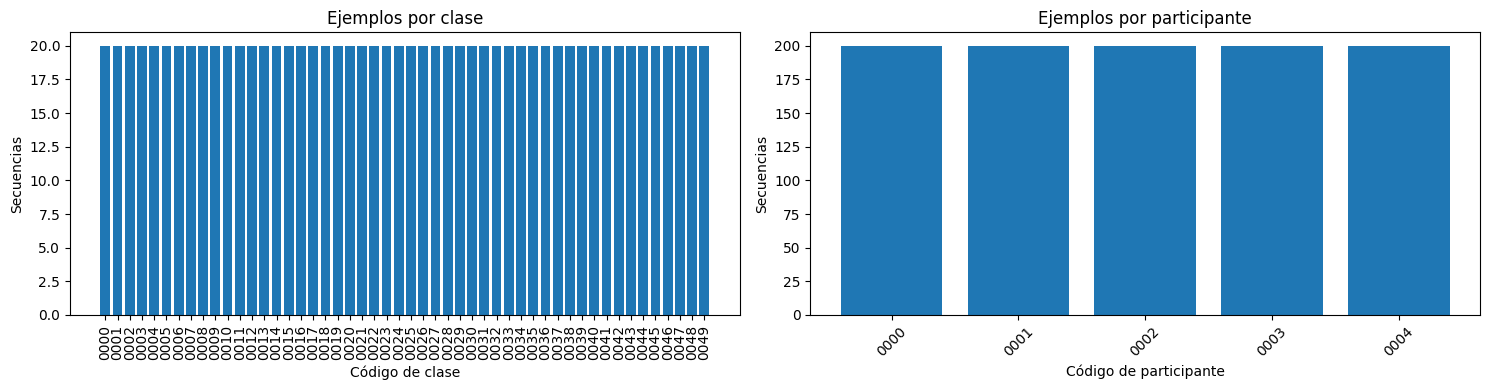

Rango de tamaños de clase: 20 - 20


In [5]:
class_counts = np.bincount(y, minlength=len(class_names))
signer_names, signer_counts = np.unique(signers, return_counts=True)
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].bar(class_names, class_counts)
axes[0].set(title="Ejemplos por clase", xlabel="Código de clase", ylabel="Secuencias")
axes[0].tick_params(axis="x", rotation=90)
axes[1].bar(signer_names, signer_counts)
axes[1].set(title="Ejemplos por participante", xlabel="Código de participante", ylabel="Secuencias")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()
print("Rango de tamaños de clase:", int(class_counts.min()), "-", int(class_counts.max()))

## 3. Entrenar el Transformer

Con cinco participantes, el modo `subject` usa tres para entrenamiento, uno para validación y uno para prueba: 600/200/200 secuencias. Cada clase tiene 12 ejemplos de entrenamiento y 4 en cada conjunto reservado; es un split balanceado, pero mide la difícil generalización a un participante no visto. El modo `random` reparte cada clase en 80/10/10 y mezcla participantes: úsalo solo para comprobar si el modelo aprende las clases, no como medición de generalización. Una línea base no neuronal alcanzó aproximadamente 19.5% con split aleatorio y 6.5% con firmante reservado, lo que muestra un fuerte cambio de dominio entre participantes.

La normalización, arquitectura y aumentación cambiaron: ejecuta esta celda para volver a entrenar. El Transformer ahora es más pequeño (64 unidades, una capa), tiene más dropout y weight decay, parada temprana por pérdida de validación y reducción de learning rate basada en esa pérdida. La aumentación solo afecta entrenamiento (rotación, escala, traslación, ruido leve, deformación temporal y oclusión sintética temporal/landmarks); validación y prueba permanecen originales. Cada modo guarda un checkpoint distinto.

In [5]:
from types import SimpleNamespace
import importlib
import inspect
import landmark_recognition.data as landmark_data
import landmark_recognition.models as landmark_models
import landmark_recognition.train_model as landmark_train

# Recargar en orden: train_model importa estos módulos y conserva sus símbolos.
importlib.reload(landmark_data)
importlib.reload(landmark_models)
importlib.reload(landmark_train)
print("Código de entrenamiento cargado desde:", landmark_train.__file__)
trainer_source = inspect.getsource(landmark_train.train)
required_log_fields = (
    "train_accuracy=", "val_loss=", "lr=", "Training augmentation:",
    "Early stopping at epoch", "best_epoch",
)
missing_fields = [field for field in required_log_fields if field not in trainer_source]
if missing_fields:
    raise RuntimeError(
        f"El train_model.py de Drive es una versión antigua (faltan {missing_fields}). "
        "Copia los archivos actualizados desde Codigo a Drive y reinicia el entorno de Colab."
    )
print("Verificación: trainer actualizado (train_accuracy, val_loss, lr).")

EPOCHS = 100
BATCH_SIZE = 16
LEARNING_RATE = 0.001
SPLIT_MODE = "subject"  # Cambia a "random" para diagnosticar aprendizaje con firmantes compartidos.
CHECKPOINT_PATH = PROJECT_DIR / "checkpoints" / f"transformer_{SPLIT_MODE}.pth"

landmark_train.train(SimpleNamespace(
    dataset=DATASET_PATH,
    architecture="transformer",
    output=CHECKPOINT_PATH,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    learning_rate=LEARNING_RATE,
    validation_signer="",
    test_signer="",
    split_mode=SPLIT_MODE,
    no_augmentation=False,
    seed=42,
    early_stopping_patience=15,
    early_stopping_min_delta=0.01,
))

Código de entrenamiento cargado desde: /content/drive/MyDrive/FASE 2 IA/Fase 2/Codigo/landmark_recognition/train_model.py
Verificación: trainer actualizado (train_accuracy, val_loss, lr).
Split mode=subject; train=600, validation=200, test=200
Participants: train=['0000', '0001', '0002'], validation=['0003'], test=['0004']
train class counts: min=12, max=12, missing=[]
validation class counts: min=4, max=4, missing=[]
test class counts: min=4, max=4, missing=[]
Training augmentation: enabled (online; labels unchanged)
Epoch 001/100: loss=4.1262, train_accuracy=0.0767, val_loss=3.9671, val_accuracy=0.0350, lr=0.001
Epoch 002/100: loss=3.9993, train_accuracy=0.1067, val_loss=3.9313, val_accuracy=0.0250, lr=0.001
Epoch 003/100: loss=3.8939, train_accuracy=0.1083, val_loss=3.8433, val_accuracy=0.0450, lr=0.001
Epoch 004/100: loss=3.7268, train_accuracy=0.1333, val_loss=3.7372, val_accuracy=0.0600, lr=0.001
Epoch 005/100: loss=3.5596, train_accuracy=0.2050, val_loss=3.6341, val_accuracy=0.0

## 4. Curvas de entrenamiento

El checkpoint conserva la pérdida y exactitud de entrenamiento, pérdida y exactitud de validación y la tasa de aprendizaje por época. Si entrenamiento mejora y validación permanece baja, hay una brecha de generalización; si ambas métricas se quedan cerca de 2%, el modelo no está aprendiendo por encima del azar (50 clases).

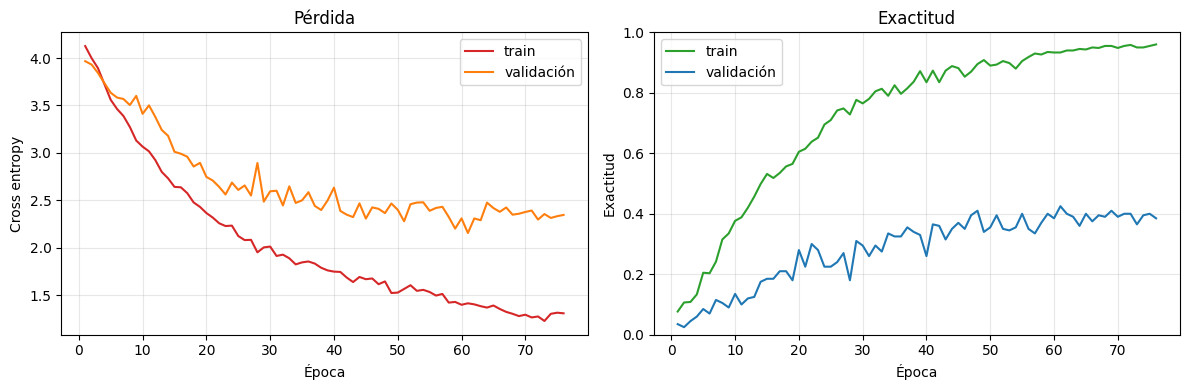

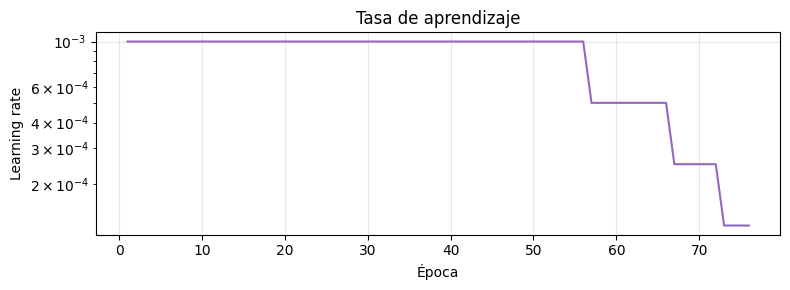

Mejor época (por menor pérdida de validación): 61
Pérdida de validación seleccionada: 2.156
Exactitud de validación en esa época: 0.425
Exactitud de prueba: 0.59


In [ ]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
checkpoint = torch.load(CHECKPOINT_PATH, map_location="cpu", weights_only=True)
history = checkpoint["history"]
epochs = np.arange(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs, history["train_loss"], color="tab:red", label="train")
axes[0].plot(epochs, history["validation_loss"], color="tab:orange", label="validación")
axes[0].set(title="Pérdida", xlabel="Época", ylabel="Cross entropy")
axes[0].legend()
axes[0].grid(True, alpha=0.3)
axes[1].plot(epochs, history["train_accuracy"], color="tab:green", label="train")
axes[1].plot(epochs, history["validation_accuracy"], color="tab:blue", label="validación")
axes[1].set(title="Exactitud", xlabel="Época", ylabel="Exactitud", ylim=(0, 1))
axes[1].legend()
axes[1].grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

lr_fig, lr_ax = plt.subplots(figsize=(8, 3))
lr_ax.plot(epochs, history["learning_rate"], color="tab:purple")
lr_ax.set_yscale("log")
lr_ax.set(title="Tasa de aprendizaje", xlabel="Época", ylabel="Learning rate")
lr_ax.grid(True, alpha=0.3)
lr_fig.tight_layout()
plt.show()
print(f"Mejor época (por menor pérdida de validación): {checkpoint['best_epoch']}")
print(f"Pérdida de validación seleccionada: {checkpoint['validation_loss']:.3f}")
print(f"Exactitud de validación en esa época: {checkpoint['validation_accuracy']:.3f}")
print(f"Exactitud de prueba: {checkpoint['test_accuracy']}")

## 5. Matriz de confusión y exactitud por clase

Estas métricas se calculan en las predicciones guardadas del participante reservado para prueba. Las filas son clases reales y las columnas clases predichas.

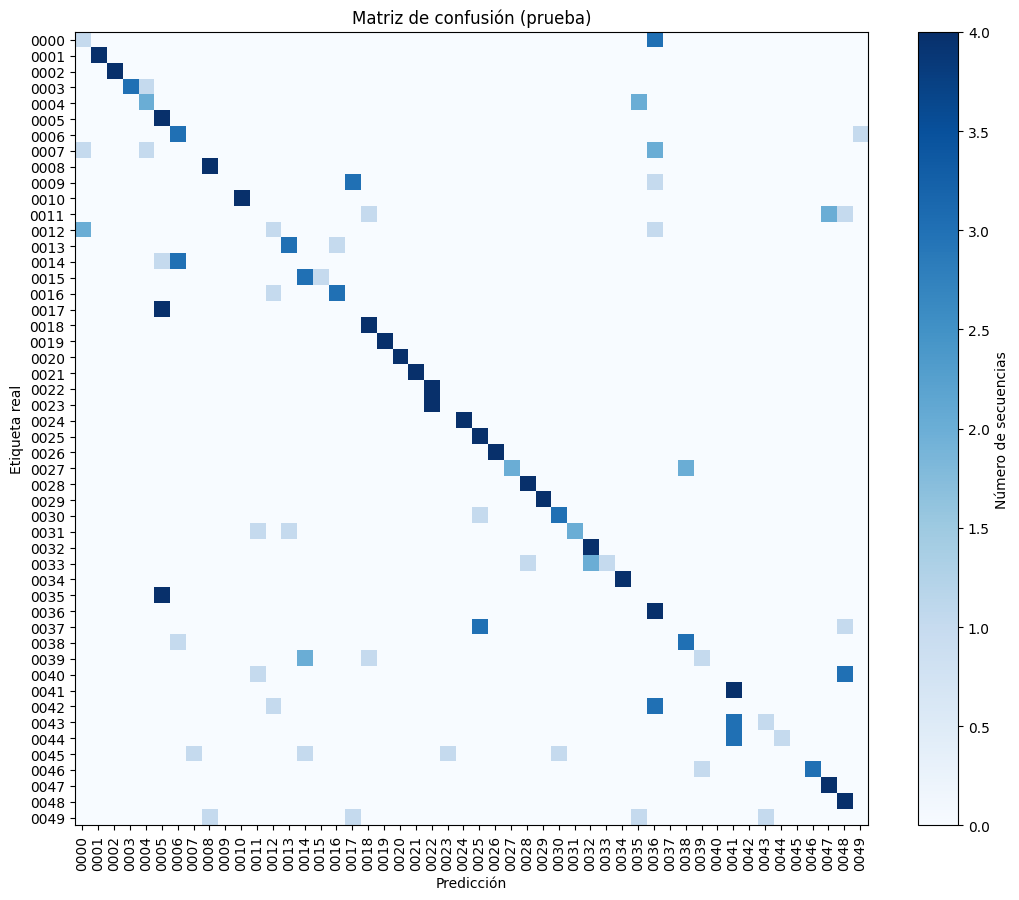

Clase 0048: exactitud=1.000, ejemplos=4
Clase 0047: exactitud=1.000, ejemplos=4
Clase 0032: exactitud=1.000, ejemplos=4
Clase 0041: exactitud=1.000, ejemplos=4
Clase 0034: exactitud=1.000, ejemplos=4
Clase 0036: exactitud=1.000, ejemplos=4
Clase 0001: exactitud=1.000, ejemplos=4
Clase 0010: exactitud=1.000, ejemplos=4
Clase 0019: exactitud=1.000, ejemplos=4
Clase 0018: exactitud=1.000, ejemplos=4


In [ ]:
test_targets = np.asarray(checkpoint["test_targets"], dtype=int)
test_predictions = np.asarray(checkpoint["test_predictions"], dtype=int)
if len(test_targets) == 0:
    raise ValueError("El checkpoint no tiene predicciones de prueba; vuelve a entrenar con al menos 3 participantes.")

confusion = np.zeros((len(class_names), len(class_names)), dtype=int)
np.add.at(confusion, (test_targets, test_predictions), 1)
fig, ax = plt.subplots(figsize=(11, 9))
image = ax.imshow(confusion, cmap="Blues", interpolation="nearest")
ax.set(title="Matriz de confusión (prueba)", xlabel="Predicción", ylabel="Etiqueta real")
ax.set_xticks(np.arange(len(class_names)), labels=class_names, rotation=90)
ax.set_yticks(np.arange(len(class_names)), labels=class_names)
fig.colorbar(image, ax=ax, label="Número de secuencias")
plt.tight_layout()
plt.show()

support = confusion.sum(axis=1)
per_class_accuracy = np.divide(
    confusion.diagonal(), support,
    out=np.full(len(class_names), np.nan), where=support > 0
)
for class_index in np.argsort(np.nan_to_num(per_class_accuracy, nan=-1))[-10:][::-1]:
    if support[class_index]:
        print(f"Clase {class_names[class_index]}: exactitud={per_class_accuracy[class_index]:.3f}, ejemplos={support[class_index]}")

## 6. Visualizar una secuencia de pose

Se muestran trayectorias normalizadas aproximadas x/y de los puntos de hombro y muñeca de pose. Los puntos son los índices estándares de pose de MediaPipe.

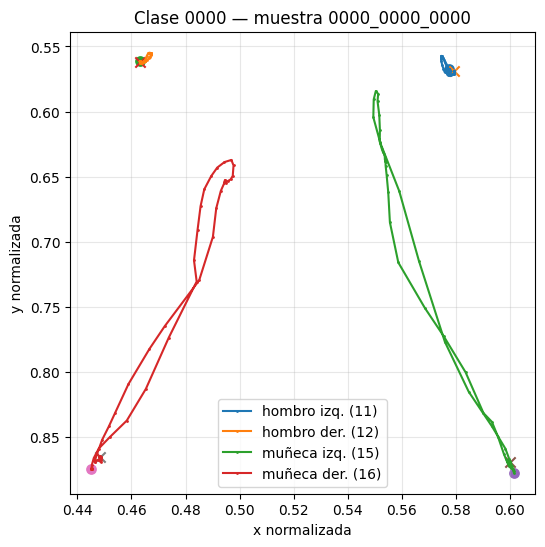

In [ ]:
sample_index = 0
pose_indices = {"hombro izq. (11)": 11, "hombro der. (12)": 12, "muñeca izq. (15)": 15, "muñeca der. (16)": 16}
fig, ax = plt.subplots(figsize=(6, 6))
for name, point_index in pose_indices.items():
    trajectory = X[sample_index, :, point_index, :2]
    ax.plot(trajectory[:, 0], trajectory[:, 1], marker=".", markersize=2, label=name)
    ax.scatter(trajectory[0, 0], trajectory[0, 1], s=45, marker="o")
    ax.scatter(trajectory[-1, 0], trajectory[-1, 1], s=55, marker="x")
ax.invert_yaxis()
ax.set(title=f"Clase {class_names[y[sample_index]]} — muestra {sample_ids[sample_index]}", xlabel="x normalizada", ylabel="y normalizada")
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()

## 7. Probar una grabación con OpenCV y MediaPipe (opcional)

Para inferencia en cámara, instala las dependencias de `requirements.txt` y ejecuta desde una terminal. Una webcam conectada al equipo donde corre el kernel es necesaria para `--source 0`; también puedes pasar un archivo de video.

In [ ]:
VIDEO_SOURCE = "0"  # Reemplaza por una ruta, por ejemplo r"C:\\videos\\prueba.mp4"
print("Comando para abrir webcam/video en ventana OpenCV:")
print(f'python -m landmark_recognition.predict_video --checkpoint "{CHECKPOINT_PATH}" --source "{VIDEO_SOURCE}"')
print("Pulsa q en la ventana de video para cerrarla.")

Comando para abrir webcam/video en ventana OpenCV:
python -m landmark_recognition.predict_video --checkpoint "/content/drive/MyDrive/FASE 2 IA/Fase 2/Codigo/landmark_recognition/checkpoints/transformer_subject.pth" --source "0"
Pulsa q en la ventana de video para cerrarla.


In [2]:
%pip install -q mediapipe

In [1]:
%pip install mediapipe==0.10.30

In [3]:
from landmark_recognition.colab_webcam import run_colab_webcam

WEBCAM_CHECKPOINT_PATH = PROJECT_DIR / "checkpoints" / "transformer_subject.pth"
if "SPLIT_MODE" in globals() and CHECKPOINT_PATH.is_file():
    WEBCAM_CHECKPOINT_PATH = CHECKPOINT_PATH
elif not WEBCAM_CHECKPOINT_PATH.is_file():
    WEBCAM_CHECKPOINT_PATH = PROJECT_DIR / "checkpoints" / "transformer.pth"
print(f"Checkpoint de webcam: {WEBCAM_CHECKPOINT_PATH}")
run_colab_webcam(WEBCAM_CHECKPOINT_PATH)

Checkpoint de webcam: /content/drive/MyDrive/FASE 2 IA/Fase 2/Codigo/landmark_recognition/checkpoints/transformer_subject.pth


<IPython.core.display.Javascript object>

TimeoutError: La cámara no respondió dentro de 30 segundos. Comprueba que el bloque JavaScript se haya ejecutado y que el video aparezca en la salida de esta celda.